In [7]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import joblib
import os


from google.colab import files




In [8]:
# ==========================================
# DADOS DE JANEIRO DE 2026
# ==========================================

arquivo_2026 = "/transacoes_jan2026.csv"

df_2026 = pd.read_csv(arquivo_2026)

print("=== DATASET ORIGINAL — JANEIRO 2026 ===")
print("Dimensões:", df_2026.shape)

display(df_2026.head())

print("\nColunas:")
print(df_2026.columns.tolist())


=== DATASET ORIGINAL — JANEIRO 2026 ===
Dimensões: (44451, 14)


,datahora_transacao,nome_estabelecimento,tipo_estabelecimento,valor_transacao,nome_cliente,cidade,device_type,is_new_device,temperatura_celsius,codigo_postal,score_interno,turno,valor_categoria,cidade_regiao
0,2026-01-01 00:00:00,Pharmacy Z,Pharmacy,21.72,Cliente_16241,Curitiba,desktop,False,17.4,36135-417,691,madrugada,baixo,Sul
1,2026-01-01 00:01:00,Electronics Store,Retail,28.70,Cliente_10027,Porto Alegre,mobile,False,11.9,83134-620,292,madrugada,baixo,Sul
2,2026-01-01 00:02:00,Restaurant X,Food & Beverage,34.55,Cliente_13606,Porto Alegre,desktop,False,15.0,41309-759,81,madrugada,medio,Sul
3,2026-01-01 00:03:00,Gas Station,Fuel,57.53,Cliente_7302,Belo Horizonte,desktop,False,23.5,15793-404,54,madrugada,medio,Sudeste
4,2026-01-01 00:04:00,Gas Station,Fuel,149.50,Cliente_20061,Recife,desktop,False,28.1,73917-730,31,madrugada,alto,Nordeste



Colunas:
['datahora_transacao', 'nome_estabelecimento', 'tipo_estabelecimento', 'valor_transacao', 'nome_cliente', 'cidade', 'device_type', 'is_new_device', 'temperatura_celsius', 'codigo_postal', 'score_interno', 'turno', 'valor_categoria', 'cidade_regiao']


In [9]:
# ==========================================
# CARREGAR MODELO TREINADO
# ==========================================

artefato = joblib.load(
    "/random_forest_final_limiar_053.joblib"
)

modelo_rf = artefato["modelo"]
FEATURES_FINAIS = list(artefato["features"])
limiar_rf = artefato["limiar"]

print("=== MODELO CARREGADO ===")
print("Algoritmo:", artefato["algoritmo"])
print("Features:", len(FEATURES_FINAIS))
print("Limiar:", limiar_rf)
print("\nVariáveis utilizadas:")
print(FEATURES_FINAIS)


=== MODELO CARREGADO ===
Algoritmo: Random Forest
Features: 14
Limiar: 0.53

Variáveis utilizadas:
['valor_transacao', 'score_interno', 'hora_sin', 'hora_cos', 'dia_semana', 'fim_semana', 'log_valor', 'noite_dispositivo_novo', 'nome_estabelecimento', 'tipo_estabelecimento', 'cidade', 'device_type', 'is_new_device', 'turno']


In [10]:

# ==========================================
# ENGENHARIA DE ATRIBUTOS — 2026
# ==========================================

df_predicao = df_2026.copy()

df_predicao["datahora_transacao"] = pd.to_datetime(
    df_predicao["datahora_transacao"],
    errors="coerce"
)

assert df_predicao["datahora_transacao"].notna().all(), (
    "Existem datas inválidas."
)

hora = df_predicao["datahora_transacao"].dt.hour

# Representação cíclica da hora
df_predicao["hora_sin"] = np.sin(
    2 * np.pi * hora / 24
)

df_predicao["hora_cos"] = np.cos(
    2 * np.pi * hora / 24
)

# Dia da semana
df_predicao["dia_semana"] = (
    df_predicao["datahora_transacao"].dt.dayofweek
)

# Final de semana
df_predicao["fim_semana"] = (
    df_predicao["dia_semana"] >= 5
)

# Transformação logarítmica do valor
df_predicao["log_valor"] = np.log1p(
    df_predicao["valor_transacao"]
)

# Interação entre período noturno e dispositivo novo
df_predicao["noite_dispositivo_novo"] = (
    (hora >= 18) &
    df_predicao["is_new_device"].astype(bool)
)

# Conferir se todas as features existem
faltantes = [
    coluna for coluna in FEATURES_FINAIS
    if coluna not in df_predicao.columns
]

if faltantes:
    raise ValueError(
        f"Features ausentes: {faltantes}"
    )

X_2026 = df_predicao[FEATURES_FINAIS].copy()

print("=== FEATURES PREPARADAS ===")
print("Dimensões:", X_2026.shape)
print("Valores ausentes:", X_2026.isna().sum().sum())


=== FEATURES PREPARADAS ===
Dimensões: (44451, 14)
Valores ausentes: 0


In [11]:
# ==========================================
# PREVISÃO DE FRAUDES — JANEIRO 2026
# ==========================================

assert len(X_2026) > 0
assert not X_2026.isna().any().any()
assert X_2026.columns.tolist() == FEATURES_FINAIS

indice_fraude = list(modelo_rf.classes_).index(True)

# Probabilidade de fraude
probabilidades = modelo_rf.predict_proba(
    X_2026
)[:, indice_fraude]

# Classificação usando limiar 0.50
previsoes = probabilidades >= limiar_rf

# Criar dataset de resultados
df_resultado = df_2026.copy()

df_resultado["probabilidade_fraude"] = probabilidades
df_resultado["previsao_fraude"] = previsoes

print("=== RESULTADOS — JANEIRO 2026 ===")
print("Total de transações:", len(df_resultado))
print("Fraudes previstas:", int(previsoes.sum()))
print("Transações legítimas previstas:", int((~previsoes).sum()))
print(
    "Percentual previsto de fraude:",
    f"{previsoes.mean() * 100:.2f}%"
)

display(
    df_resultado[
        [
            "datahora_transacao",
            "valor_transacao",
            "probabilidade_fraude",
            "previsao_fraude"
        ]
    ].head(10)
)


=== RESULTADOS — JANEIRO 2026 ===
Total de transações: 44451
Fraudes previstas: 3399
Transações legítimas previstas: 41052
Percentual previsto de fraude: 7.65%


,datahora_transacao,valor_transacao,probabilidade_fraude,previsao_fraude
0,2026-01-01 00:00:00,21.72,0.000000,False
1,2026-01-01 00:01:00,28.70,0.000000,False
2,2026-01-01 00:02:00,34.55,0.000000,False
3,2026-01-01 00:03:00,57.53,0.006981,False
4,2026-01-01 00:04:00,149.50,0.000000,False
5,2026-01-01 00:05:00,514.43,0.000000,False
6,2026-01-01 00:06:00,593.40,0.000000,False
7,2026-01-01 00:07:00,63.16,0.000000,False
8,2026-01-01 00:08:00,10.73,0.000000,False
9,2026-01-01 00:09:00,12.28,0.000000,False


In [12]:
from google.colab import files

# Exportar todas as transações
df_resultado.to_csv(
    "previsoes_fraude_janeiro_2026.csv",
    index=False,
    encoding="utf-8-sig"
)

# Baixar o arquivo
files.download("previsoes_fraude_janeiro_2026.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
df_conferencia = pd.read_csv(
    "previsoes_fraude_janeiro_2026.csv"
)

print("Linhas:", len(df_conferencia))
print("Colunas:", df_conferencia.columns.tolist())

display(df_conferencia.head(10))

Linhas: 44451
Colunas: ['datahora_transacao', 'nome_estabelecimento', 'tipo_estabelecimento', 'valor_transacao', 'nome_cliente', 'cidade', 'device_type', 'is_new_device', 'temperatura_celsius', 'codigo_postal', 'score_interno', 'turno', 'valor_categoria', 'cidade_regiao', 'probabilidade_fraude', 'previsao_fraude']


,datahora_transacao,nome_estabelecimento,tipo_estabelecimento,valor_transacao,nome_cliente,cidade,device_type,is_new_device,temperatura_celsius,codigo_postal,score_interno,turno,valor_categoria,cidade_regiao,probabilidade_fraude,previsao_fraude
0,2026-01-01 00:00:00,Pharmacy Z,Pharmacy,21.72,Cliente_16241,Curitiba,desktop,False,17.4,36135-417,691,madrugada,baixo,Sul,0.000000,False
1,2026-01-01 00:01:00,Electronics Store,Retail,28.70,Cliente_10027,Porto Alegre,mobile,False,11.9,83134-620,292,madrugada,baixo,Sul,0.000000,False
2,2026-01-01 00:02:00,Restaurant X,Food & Beverage,34.55,Cliente_13606,Porto Alegre,desktop,False,15.0,41309-759,81,madrugada,medio,Sul,0.000000,False
3,2026-01-01 00:03:00,Gas Station,Fuel,57.53,Cliente_7302,Belo Horizonte,desktop,False,23.5,15793-404,54,madrugada,medio,Sudeste,0.006981,False
4,2026-01-01 00:04:00,Gas Station,Fuel,149.50,Cliente_20061,Recife,desktop,False,28.1,73917-730,31,madrugada,alto,Nordeste,0.000000,False
5,2026-01-01 00:05:00,Clothing Store,Retail,514.43,Cliente_16639,Rio de Janeiro,mobile,False,35.9,75863-144,568,madrugada,alto,Sudeste,0.000000,False
6,2026-01-01 00:06:00,Pharmacy Z,Pharmacy,593.40,Cliente_13788,Curitiba,mobile,False,19.9,73230-228,249,madrugada,alto,Sul,0.000000,False
7,2026-01-01 00:07:00,Online Shop 1,E-commerce,63.16,Cliente_1083,Porto Alegre,desktop,False,27.5,76229-608,655,madrugada,medio,Sul,0.000000,False
8,2026-01-01 00:08:00,Online Shop 1,E-commerce,10.73,Cliente_9347,Salvador,mobile,False,32.2,44293-143,759,madrugada,baixo,Nordeste,0.000000,False
9,2026-01-01 00:09:00,Clothing Store,Retail,12.28,Cliente_14558,Recife,mobile,False,29.9,88646-278,880,madrugada,baixo,Nordeste,0.000000,False


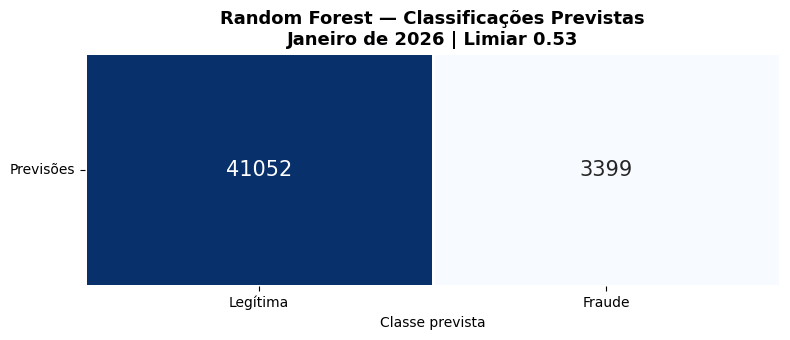

In [14]:
# ==========================================
# CLASSIFICAÇÕES — RANDOM FOREST
# JANEIRO DE 2026
# ==========================================

previsoes = df_resultado["previsao_fraude"].astype(bool)

legitimas = int((~previsoes).sum())
fraudes = int(previsoes.sum())

# Tabela de resultados
tabela = pd.DataFrame(
    {
        "Legítima": [legitimas],
        "Fraude": [fraudes]
    },
    index=["Previsões"]
)

# Gráfico
fig, ax = plt.subplots(figsize=(8, 3.5))

sns.heatmap(
    tabela,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=1,
    linecolor="white",
    cbar=False,
    annot_kws={"size": 15},
    ax=ax
)

ax.set_title(
    "Random Forest — Classificações Previstas\n"
    f"Janeiro de 2026 | Limiar {limiar_rf:.2f}",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Classe prevista")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

